# UK gilt 5s30s steepener: supporting analysis

**Data.** Bank of England yield curves (OIS and nominal government liability curves), daily from January 2016 to
5 October 2026, plus a snapshot of conventional gilt prices (giltsyield.com, close 5 October 2026).

**What this notebook does**
1. Loads the six Bank of England spreadsheets.
2. Builds the fitted par 5s30s history from the zero curve.
3. Extracts the OIS-implied Bank Rate path and counts the hikes priced.
4. Regresses weekly changes in 5s30s on changes in OIS 1y1y to calibrate the target.
5. Measures volatility to size the stop, and carry and roll from the fitted curve.
6. Draws the two charts used in the one-pager.
7. Sizes the trade DV01-neutral and screens gilts rich/cheap against the Bank's curve.

**How to run.** Download the six Bank of England spreadsheets listed in `data/README.md` into the repository's `data/` folder, then Run All. The first run parses the 2016 to 2024 files, which takes a minute or two, and caches the result to `outputs/curves.pkl`. Charts and a metrics file are written to `outputs/`.

**Conventions.** Bank of England spot and instantaneous forward rates are continuously compounded. Par yields assume
semi-annual coupons. Regressions use weekly (Friday) changes with Newey-West standard errors (4 lags).

**Requirements.** pandas, numpy, scipy, matplotlib, openpyxl.

## 1. Setup

In [1]:
import json, pickle, datetime as dt
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd
import openpyxl
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
%matplotlib inline

DATA_DIR = Path("../data")                 # folder containing the six Bank of England spreadsheets
OUT_DIR = Path("../outputs"); OUT_DIR.mkdir(exist_ok=True)
FILES = {
    "ois": ["OIS_daily_data_2016_to_2024.xlsx", "OIS_daily_data_2025_to_present.xlsx", "OIS_daily_data_current_month.xlsx"],
    "glc": ["GLC_Nominal_daily_data_2016_to_2024.xlsx", "GLC_Nominal_daily_data_2025_to_present.xlsx",
            "GLC_Nominal_daily_data_current_month.xlsx"],
}
SHEETS = ["1. fwds, short end", "2. fwd curve", "3. spot, short end", "4. spot curve"]

PREWAR = pd.Timestamp("2026-02-27")        # last close before the Iran war repricing
BANK_RATE = 3.75                           # %, held on 17 Sep 2026
TWO_HIKE_PATH = [("2026-11-05", 4.00), ("2027-02-04", 4.25)]   # Fidelity International and Oxford Economics
REUTERS_PATH = [("2027-08-05", 3.50)]      # Reuters poll median: hold, then a cut in Q3 2027 (meeting date assumed)
TRADE = dict(entry=96, target=112, stop=80)  # bp, bond terms: UKT 4% 2031 vs UKT 5 3/8% 2056

NAVY, ORANGE, GREY, GREEN, RED = "#1F3A5F", "#C8641E", "#8C8C8C", "#2E7D32", "#B23B3B"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 9, "axes.titleweight": "bold", "axes.spines.top": False, "legend.frameon": False})
pd.set_option("display.precision", 2)

## 2. Load the Bank of England curves
Each file has four curve sheets: instantaneous forwards and spot rates, each at monthly points to five years
("short end") and half-yearly points further out. Archive and current-month files are stitched together, keeping
the latest value where dates overlap.

In [2]:
def read_workbook(path):
    """Return {sheet: DataFrame (dates x maturities in years)} for the four curve sheets of one file."""
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    out = {}
    for sheet in SHEETS:
        if sheet not in wb.sheetnames:
            continue
        rows = list(wb[sheet].iter_rows(values_only=True))
        years_row = next(r for r in rows[:6] if r and r[0] == "years:")
        mats = [float(x) if isinstance(x, (int, float)) else np.nan for x in years_row[1:]]
        idx, recs = [], []
        for r in rows[5:]:
            if isinstance(r[0], dt.datetime):
                idx.append(r[0])
                recs.append([float(v) if isinstance(v, (int, float)) else np.nan for v in r[1:len(mats) + 1]])
        df = pd.DataFrame(recs, index=pd.DatetimeIndex(idx), columns=np.round(mats, 4))
        out[sheet] = df.loc[:, ~np.isnan(df.columns.values.astype(float))]
    wb.close()
    return out

cache = OUT_DIR / "curves.pkl"
if cache.exists():
    curves = pickle.load(open(cache, "rb"))
else:
    curves = {}
    for key, files in FILES.items():
        parts = {s: [] for s in SHEETS}
        for f in files:
            for s, df in read_workbook(DATA_DIR / f).items():
                parts[s].append(df)
        for s in SHEETS:
            df = pd.concat(parts[s]).sort_index()
            curves[(key, s)] = df[~df.index.duplicated(keep="last")].dropna(how="all")
    pickle.dump(curves, open(cache, "wb"))

glc_spot, glc_short = curves[("glc", "4. spot curve")], curves[("glc", "3. spot, short end")]
ois_spot, ois_short_spot = curves[("ois", "4. spot curve")], curves[("ois", "3. spot, short end")]
ois_fwd_m = curves[("ois", "1. fwds, short end")]
LAST = glc_spot.index.max()
pd.DataFrame({f"{k[0]} | {k[1]}": [v.index.min().date(), v.index.max().date(), v.shape[0], v.shape[1]]
              for k, v in curves.items()}, index=["first", "last", "days", "maturities"]).T

,first,last,days,maturities
"ois | 1. fwds, short end",2016-01-04,2026-10-05,2718,60
ois | 2. fwd curve,2016-01-04,2026-10-05,2717,50
"ois | 3. spot, short end",2016-01-04,2026-10-05,2718,60
ois | 4. spot curve,2016-01-04,2026-10-05,2717,50
"glc | 1. fwds, short end",2016-01-04,2026-10-05,2718,60
glc | 2. fwd curve,2016-01-04,2026-10-05,2718,80
"glc | 3. spot, short end",2016-01-04,2026-10-05,2718,60
glc | 4. spot curve,2016-01-04,2026-10-05,2718,80


### Check: the spot rates are continuously compounded
If they are, each spot rate equals the average of the instantaneous forwards up to that maturity.

In [3]:
f = ois_fwd_m.loc[LAST].values; mats = ois_fwd_m.columns.values.astype(float)
spot = ois_short_spot.loc[LAST].values
cum = np.cumsum((np.r_[f[0], f[:-1]] + f) / 2 * np.diff(np.r_[0, mats]))
pd.DataFrame({"maturity (y)": mats, "spot %": spot, "average forward %": cum / mats}).iloc[[2, 11, 23, 59]].round(3)

,maturity (y),spot %,average forward %
2,0.25,3.90,3.93
11,1.00,4.34,4.35
23,2.00,4.59,4.59
59,5.00,4.70,4.70


## 3. Fitted par 5s30s history
Par yields are computed from the fitted zero curve with semi-annual coupons, so the spread is comparable with
quoted gilt yields. Where the six-month point is missing it is filled from the monthly short-end sheet.

In [4]:
def zero_row(date):
    """Continuously compounded zero curve on a 0.5y grid to 40y for one date."""
    row = glc_spot.loc[date].copy().astype(float)
    if np.isnan(row.get(0.5, np.nan)) and date in glc_short.index:
        col = min(glc_short.columns, key=lambda c: abs(float(c) - 0.5))
        row[0.5] = glc_short.loc[date, col]
    mats = np.array([float(c) for c in row.index]); ok = ~np.isnan(row.values)
    return mats[ok], row.values[ok]

def par_yield(mats, z, T):
    cs = CubicSpline(mats, z, extrapolate=True)
    t = np.arange(0.5, T + 1e-9, 0.5)
    df = np.exp(-cs(t) / 100 * t)
    return 2 * (1 - df[-1]) / df.sum() * 100

def fwd_par_yield(mats, z, T, h=0.25):
    """Par yield of a T-year bond starting h years forward, implied by today's curve."""
    cs = CubicSpline(mats, z, extrapolate=True)
    df0 = np.exp(-cs(h) / 100 * h)
    t = h + np.arange(0.5, T + 1e-9, 0.5)
    df = np.exp(-cs(t) / 100 * t) / df0
    return 2 * (1 - df[-1]) / df.sum() * 100

rows = []
for d in glc_spot.index:
    mats, z = zero_row(d)
    if len(mats) < 20 or mats.min() > 1.0 or mats.max() < 30:
        continue
    rows.append((d, par_yield(mats, z, 5), par_yield(mats, z, 30)))
par = pd.DataFrame(rows, columns=["date", "par5", "par30"]).set_index("date")
par["s530"] = (par["par30"] - par["par5"]) * 100
s530 = par["s530"]
par.tail()

,par5,par30,s530
date,,,
2026-09-29,4.99,5.86,87.49
2026-09-30,4.98,5.89,90.67
2026-10-01,4.96,5.92,96.00
2026-10-02,4.92,5.84,91.87
2026-10-05,4.98,5.90,92.46


## 4. OIS 1y1y and the OIS-implied Bank Rate path

In [5]:
ois = pd.DataFrame({"z1": ois_spot[1.0], "z2": ois_spot[2.0]})
ois["f1y1y"] = 2 * ois["z2"] - ois["z1"]          # one-year rate, one year forward (continuous compounding)

def ois_path(date):
    """Monthly instantaneous OIS forwards from `date`, indexed by calendar date."""
    f = ois_fwd_m.loc[date].astype(float)
    months = np.array([float(c) for c in f.index]) * 12
    return pd.Series(f.values, index=pd.DatetimeIndex([date + pd.DateOffset(months=int(round(m))) for m in months]))

def at(path, ts):
    """Linear interpolation of a path at a calendar date."""
    x = path.index.values.astype("datetime64[D]").astype(float)
    return float(np.interp(np.datetime64(pd.Timestamp(ts).date(), "D").astype(float), x, path.values))

p_now, p_pre = ois_path(LAST), ois_path(PREWAR)
sonia_now = float(ois_short_spot.loc[LAST].iloc[0])     # one-month OIS as the current SONIA proxy
sonia_pre = float(ois_short_spot.loc[PREWAR].iloc[0])
basis = BANK_RATE - sonia_now                             # SONIA to Bank Rate basis

horizons = {"End-2026": "2026-12-31", "End-Q1 2027": "2027-03-31", "Mid-2027": "2027-06-30",
            "End-2027": "2027-12-31", "End-2028": "2028-12-31"}
priced = pd.DataFrame({
    "OIS forward %": {k: at(p_now, t) for k, t in horizons.items()},
    "hikes priced (bp)": {k: (at(p_now, t) - sonia_now) * 100 for k, t in horizons.items()},
    "pre-war, priced (bp)": {k: (at(p_pre, t) - sonia_pre) * 100 for k, t in horizons.items()},
})
peak_val, peak_date = float(p_now[:"2029-12-31"].max()), p_now[:"2029-12-31"].idxmax()
fwd_2028_31 = float(p_now["2028-01-01":"2031-12-31"].mean())
excess_peak = (peak_val + basis - 4.25) * 100
print(f"Current SONIA proxy {sonia_now:.3f}%, basis to Bank Rate {abs(basis * 100):.1f}bp")
print(f"Peak {peak_val:.2f}% around {peak_date:%b %Y}; excess over a 4.25% peak: {excess_peak:.0f}bp")
print(f"Average OIS forward 2028 to 2031: {fwd_2028_31:.2f}%")
priced.round(1)

Current SONIA proxy 3.750%, basis to Bank Rate 0.0bp
Peak 4.86% around Apr 2028; excess over a 4.25% peak: 61bp
Average OIS forward 2028 to 2031: 4.78%


,OIS forward %,hikes priced (bp),"pre-war, priced (bp)"
End-2026,4.1,32.3,-43.6
End-Q1 2027,4.4,64.0,-42.6
Mid-2027,4.6,86.4,-40.3
End-2027,4.8,108.6,-33.6
End-2028,4.8,104.4,-16.5


## 5. Where 5s30s stands

In [6]:
cur, pre = s530.loc[LAST], s530.loc[PREWAR]
last_year = s530[s530.index > LAST - pd.Timedelta(days=365)]
snapshot = pd.Series({
    "5s30s now (bp)": cur, "5s30s on 27 Feb 2026 (bp)": pre, "change since 27 Feb (bp)": cur - pre,
    "OIS 1y1y change since 27 Feb (bp)": (ois.loc[LAST, "f1y1y"] - ois.loc[PREWAR, "f1y1y"]) * 100,
    "percentile, 10 years": (s530 < cur).mean() * 100, "percentile, past year": (last_year < cur).mean() * 100,
    "z-score, 10 years": (cur - s530.mean()) / s530.std(),
    "past-year high (bp)": last_year.max(), "past-year low (bp)": last_year.min(),
})
print("Around the BoE's QT decision (17 Sep):")
print(s530["2026-09-15":"2026-09-22"].round(1).to_string())
snapshot.round(1)

Around the BoE's QT decision (17 Sep):
date
2026-09-15    90.2
2026-09-16    94.9
2026-09-17    87.7
2026-09-18    77.1
2026-09-21    83.1
2026-09-22    85.1


5s30s now (bp)                        92.5
5s30s on 27 Feb 2026 (bp)            125.7
change since 27 Feb (bp)             -33.2
OIS 1y1y change since 27 Feb (bp)    156.8
percentile, 10 years                  62.0
percentile, past year                  5.1
z-score, 10 years                      0.2
past-year high (bp)                  137.2
past-year low (bp)                    77.1
dtype: float64

## 6. Calibrating the target: 5s30s against priced hikes
Weekly changes in par 5s30s regressed on weekly changes in OIS 1y1y. A negative beta means the curve steepens when
hikes are priced out of the front end.

In [7]:
def ols_newey_west(y, x, lags=4):
    X = np.column_stack([np.ones(len(x)), x])
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b
    XtX_inv = np.linalg.inv(X.T @ X)
    S = (X * e[:, None]).T @ (X * e[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (X[L:] * e[L:, None]).T @ (X[:-L] * e[:-L, None])
        S += w * (G + G.T)
    V = XtX_inv @ S @ XtX_inv
    r2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
    return b[1], b[1] / np.sqrt(V[1, 1]), r2, len(y)

weekly = pd.concat([s530, ois["f1y1y"] * 100], axis=1).dropna().resample("W-FRI").last().dropna().diff().dropna()
reg = pd.DataFrame({name: ols_newey_west(weekly.loc[start:, "s530"].values, weekly.loc[start:, "f1y1y"].values)
                    for name, start in [("2016 to 2026", "2016-01-01"), ("2022 to 2026", "2022-01-01"), ("2026 YTD", "2026-01-01")]},
                   index=["beta", "t-stat", "R-squared", "weeks"]).T
print(f"Correlation of weekly changes in 2026: {weekly.loc['2026'].corr().iloc[0, 1]:.2f}")
reg.round(2)

Correlation of weekly changes in 2026: -0.60


,beta,t-stat,R-squared,weeks
2016 to 2026,-0.26,-9.13,0.21,561.0
2022 to 2026,-0.27,-8.33,0.24,249.0
2026 YTD,-0.22,-4.06,0.36,41.0


In [8]:
beta = reg.loc["2016 to 2026", "beta"]
cur_1y1y = ois.loc[LAST, "f1y1y"]
scenarios = pd.DataFrame({
    "1y1y in scenario (%)": {"Two hikes to 4.25% (base)": 4.25 - basis, "Reuters median (cut in Q3 2027)": 3.55},
})
scenarios["change in 1y1y (bp)"] = (scenarios["1y1y in scenario (%)"] - cur_1y1y) * 100
scenarios["implied 5s30s move (bp)"] = beta * scenarios["change in 1y1y (bp)"]
scenarios.round(1)

,1y1y in scenario (%),change in 1y1y (bp),implied 5s30s move (bp)
Two hikes to 4.25% (base),4.3,-58.8,15.4
Reuters median (cut in Q3 2027),3.6,-128.9,33.8


## 7. Volatility, stop sizing, and carry and roll

In [9]:
dd = s530.diff().dropna()
vol = pd.Series({"daily, past year": dd[dd.index > LAST - pd.Timedelta(days=365)].std(), "daily, 10 years": dd.std()})
vol["3-month, past year"] = vol["daily, past year"] * np.sqrt(63)
vol["3-month, 10 years"] = vol["daily, 10 years"] * np.sqrt(63)

mats, z = zero_row(LAST)
fwd_s530 = (fwd_par_yield(mats, z, 30) - fwd_par_yield(mats, z, 5)) * 100
carry_roll = cur - fwd_s530        # positive: the steepener earns this if the curve is unchanged for 3 months

risk = TRADE["entry"] - TRADE["stop"]; reward = TRADE["target"] - TRADE["entry"]
print(f"3-month carry and roll on the fitted curve: {carry_roll:+.1f}bp (3m forward 5s30s {fwd_s530:.1f}bp)")
print(f"Stop distance {risk}bp = {risk / vol['3-month, past year']:.2f} standard deviations of 3-month moves (past year)")
print(f"Risk/reward on spread {reward / risk:.1f}x; including 6 months of carry and roll {(reward + 2 * carry_roll) / risk:.1f}x")
vol.round(1).to_frame("bp")

3-month carry and roll on the fitted curve: +4.3bp (3m forward 5s30s 88.2bp)
Stop distance 16bp = 0.77 standard deviations of 3-month moves (past year)
Risk/reward on spread 1.0x; including 6 months of carry and roll 1.5x


,bp
"daily, past year",2.6
"daily, 10 years",3.3
"3-month, past year",20.7
"3-month, 10 years",26.3


## 8. Charts used in the one-pager

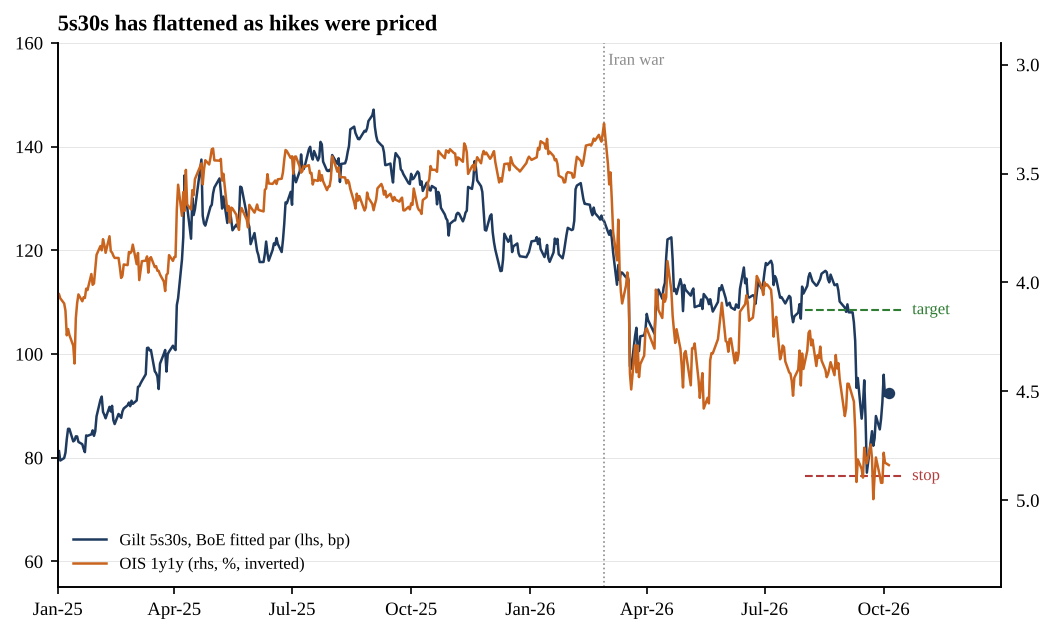

In [10]:
start = "2025-01-01"
s, f1 = s530[start:], ois["f1y1y"][start:]
fig, ax = plt.subplots(figsize=(7.1, 4.3), dpi=150)
l1, = ax.plot(s.index, s.values, color=NAVY, lw=1.2, label="Gilt 5s30s, BoE fitted par (lhs, bp)")
ax2 = ax.twinx(); ax2.invert_yaxis(); ax2.spines["top"].set_visible(False)
l2, = ax2.plot(f1.index, f1.values, color=ORANGE, lw=1.2, label="OIS 1y1y (rhs, %, inverted)")
ax.axvline(PREWAR, color=GREY, lw=0.8, ls=":"); ax.text(PREWAR, 158, " Iran war", fontsize=8, color=GREY, va="top")
x0, x1 = pd.Timestamp("2026-08-01"), s.index.max() + pd.Timedelta(days=12)
for lvl, col, lab in [(cur + reward, GREEN, "target"), (cur - risk, RED, "stop")]:
    ax.hlines([lvl], x0, x1, colors=col, lw=1, ls="--"); ax.text(x1 + pd.Timedelta(days=6), lvl, lab, color=col, fontsize=8, va="center")
ax.scatter([s.index.max()], [cur], color=NAVY, s=20, zorder=5)
ax.set_ylim(55, 160); ax2.set_ylim(5.4, 2.9); ax.set_xlim(pd.Timestamp(start), x1 + pd.Timedelta(days=75))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_title("5s30s has flattened as hikes were priced", loc="left")
ax.legend(handles=[l1, l2], loc="lower left", fontsize=8); ax.grid(axis="y", lw=0.3, alpha=0.5)
fig.tight_layout(); fig.savefig(OUT_DIR / "chart_spread.png", dpi=300); plt.show()

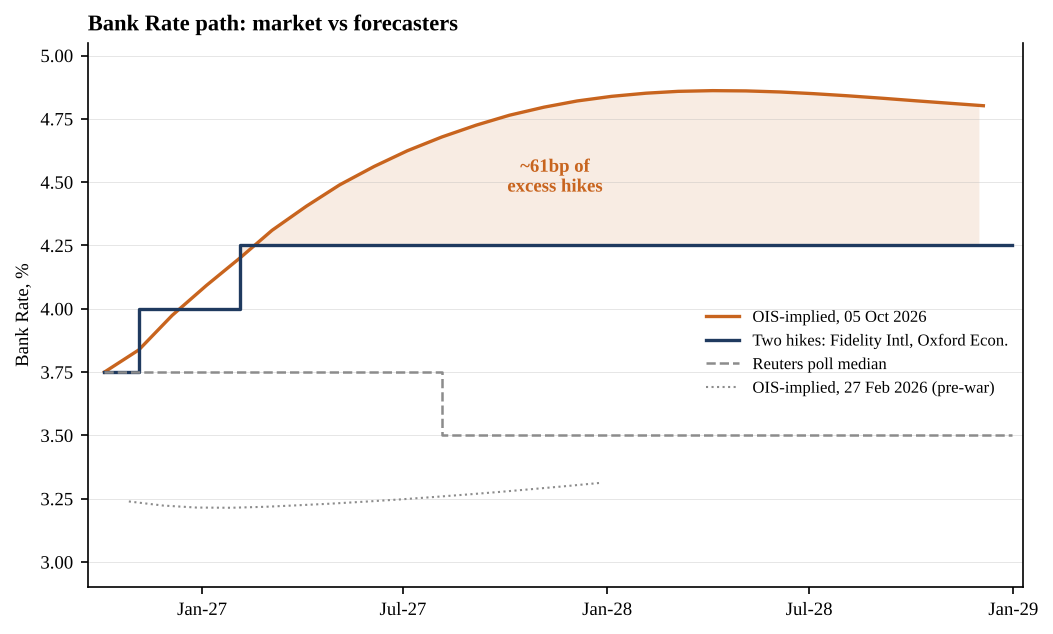

In [11]:
def step_path(points, start_date, start_rate, end_date):
    xs, ys = [pd.Timestamp(start_date)], [start_rate]
    for t, v in points:
        xs.append(pd.Timestamp(t)); ys.append(v)
    return xs + [end_date], ys + [ys[-1]]

end = pd.Timestamp("2028-12-31")
pn = p_now[:end] + basis
pp = p_pre[(p_pre.index >= pd.Timestamp("2026-10-01")) & (p_pre.index <= pd.Timestamp("2027-12-31"))]
two = step_path(TWO_HIKE_PATH, LAST, BANK_RATE, end)
reu = step_path(REUTERS_PATH, LAST, BANK_RATE, end)
fig, ax = plt.subplots(figsize=(7.1, 4.3), dpi=150)
ax.plot([LAST] + list(pn.index), [BANK_RATE] + list(pn.values), color=ORANGE, lw=1.6, label=f"OIS-implied, {LAST:%d %b %Y}")
ax.step(*two, where="post", color=NAVY, lw=1.6, label="Two hikes: Fidelity Intl, Oxford Econ.")
ax.step(*reu, where="post", color=GREY, lw=1.2, ls="--", label="Reuters poll median")
ax.plot(pp.index, pp.values, color=GREY, lw=1.0, ls=":", label="OIS-implied, 27 Feb 2026 (pre-war)")
xs = pd.date_range("2027-02-05", pn.index.max(), freq="7D")
ax.fill_between(xs, 4.25, np.interp(xs.values.astype("datetime64[D]").astype(float),
                pn.index.values.astype("datetime64[D]").astype(float), pn.values), color=ORANGE, alpha=0.12, lw=0)
ax.text(pd.Timestamp("2027-11-15"), 4.52, f"~{excess_peak:.0f}bp of\nexcess hikes", fontsize=9, color=ORANGE,
        ha="center", va="center", fontweight="bold")
ax.set_ylim(2.9, 5.05); ax.set_xlim(pd.Timestamp("2026-09-20"), end + pd.Timedelta(days=10))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_ylabel("Bank Rate, %"); ax.set_title("Bank Rate path: market vs forecasters", loc="left")
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.43), fontsize=8); ax.grid(axis="y", lw=0.3, alpha=0.5)
fig.tight_layout(); fig.savefig(OUT_DIR / "chart_path_ois.png", dpi=300); plt.show()

## 9. Trade construction: gilt snapshot, DV01 sizing, rich/cheap
Gilt prices are the close on 5 October 2026 (giltsyield.com, T+1 settlement on 7 October): coupon, maturity, dirty
price, modified duration and DMO yield (semi-annual).

In [12]:
GILTS_CSV = """
code,coupon_pct,maturity,dirty_price,mod_duration,dmo_yield_pct
T26A,0.375,2026-10-22,100.022,0.04,4.072
T39,4.25,2039-09-07,87.812,9.53,5.629
TR39,1.125,2039-01-31,60.858,10.89,5.587
TS28,4.5,2028-06-07,101.140,1.56,4.723
T31,4.0,2031-10-22,97.486,4.41,4.986
TG33,0.875,2033-07-31,75.802,6.42,5.160
TN28,0.125,2028-01-31,94.753,1.29,4.289
TR60,4.0,2060-01-22,73.257,15.47,5.902
T54,4.375,2054-07-31,79.228,14.23,5.975
TG71,1.625,2071-10-22,36.106,20.73,5.540
TG37,1.75,2037-09-07,69.675,9.46,5.499
T30K,4.625,2030-05-22,99.347,3.28,4.924
TG50,0.625,2050-10-22,32.657,19.71,5.949
T45,3.5,2045-01-22,74.262,12.26,5.881
T51A,1.25,2051-07-31,39.371,17.98,5.993
TG35,0.625,2035-07-31,67.445,8.29,5.315
TS29,4.125,2029-07-22,98.983,2.58,4.851
T40,4.25,2040-12-07,87.587,10.02,5.684
T56,5.375,2056-01-31,93.078,13.92,5.948
T49,4.25,2049-12-07,80.507,13.20,5.920
T32H,4.625,2032-03-07,98.868,4.69,5.034
TG40,4.375,2040-01-31,88.748,9.62,5.677
T35V,4.75,2035-10-22,97.900,7.06,5.353
TG49,1.75,2049-01-22,48.886,15.83,5.949
T29K,4.0,2029-05-22,99.420,2.42,4.852
TR4Q,4.25,2055-12-07,78.117,14.49,5.940
TR43,4.75,2043-10-22,90.440,10.89,5.847
TR63,4.0,2063-10-22,73.586,15.70,5.881
TR33,3.25,2033-01-31,90.661,5.55,5.111
TG29,0.5,2029-01-31,90.952,2.25,4.713
TR30,4.75,2030-12-07,101.223,3.68,4.845
TR28,6.0,2028-12-07,104.750,1.98,4.647
TG65,2.5,2065-07-22,49.638,17.94,5.820
T46,4.25,2046-12-07,82.187,12.34,5.892
TR29,0.875,2029-10-22,89.422,2.92,4.798
TR68,3.5,2068-07-22,64.682,16.88,5.802
T31H,4.125,2031-03-07,97.082,3.96,4.955
T52,3.75,2052-07-22,72.055,14.32,5.940
TS27,3.75,2027-03-07,100.121,0.41,4.208
TG30,0.375,2030-10-22,84.032,3.91,4.818
TR32,4.25,2032-06-07,97.787,4.89,4.992
TG38,3.75,2038-01-29,85.783,8.80,5.544
T4Q,4.25,2036-03-07,92.152,7.54,5.370
T35,4.5,2035-03-07,94.943,6.84,5.308
T42,4.5,2042-12-07,88.110,10.76,5.786
TS34,4.25,2034-07-31,94.485,6.46,5.242
TE28,4.375,2028-03-07,99.923,1.35,4.697
T34,4.625,2034-01-31,97.365,6.06,5.204
TR54,1.625,2054-10-22,42.041,17.87,5.958
TG53,1.5,2053-07-31,40.692,18.00,5.993
T27A,4.125,2027-01-29,100.775,0.31,4.141
TG47,1.5,2047-07-22,47.614,15.63,5.951
T30,4.375,2030-03-07,98.723,3.12,4.901
TG44,3.25,2044-01-22,72.500,12.04,5.865
TG28,1.625,2028-10-22,94.836,1.96,4.695
TR38,4.75,2038-12-07,94.343,8.85,5.577
TR27,4.25,2027-12-07,101.077,1.11,4.548
TR34,4.5,2034-09-07,95.713,6.52,5.226
TG31,0.25,2031-07-31,80.486,4.67,4.854
TR73,1.125,2073-10-22,28.081,23.51,5.358
T53,3.75,2053-10-22,72.071,14.37,5.974
TG61,0.5,2061-10-22,22.215,26.18,5.616
T41F,5.25,2041-01-31,96.420,9.75,5.719
TG41,1.25,2041-10-22,55.774,12.66,5.736
TG27,1.25,2027-07-22,97.852,0.77,4.382
TG57,1.75,2057-07-22,41.486,18.38,5.936
T33H,4.125,2033-03-07,94.922,5.51,5.126
T36N,4.875,2036-07-31,96.791,7.59,5.419
T37H,4.625,2037-03-07,93.763,8.04,5.466
TG46,0.875,2046-01-31,42.482,16.13,5.931
TG32,1.0,2032-01-31,81.645,5.04,5.017
"""
gilts = pd.read_csv(StringIO(GILTS_CSV)).set_index("code")
gilts.loc[["T31", "T56", "TR4Q"]]

,coupon_pct,maturity,dirty_price,mod_duration,dmo_yield_pct
code,,,,,
T31,4.00,2031-10-22,97.49,4.41,4.99
T56,5.38,2056-01-31,93.08,13.92,5.95
TR4Q,4.25,2055-12-07,78.12,14.49,5.94


In [13]:
dv01 = lambda g: g.dirty_price / 100 * g.mod_duration * 1e-4 * 1_000_000   # GBP per bp per GBP 1m nominal
long_leg, short_leg = gilts.loc["T31"], gilts.loc["T56"]
ratio = dv01(short_leg) / dv01(long_leg)
print(f"Bond spread (DMO yields): {(short_leg.dmo_yield_pct - long_leg.dmo_yield_pct) * 100:.1f}bp")
print(f"DV01 per GBP 1m: 2031 {dv01(long_leg):,.0f}, 2056 {dv01(short_leg):,.0f}; nominal ratio {ratio:.2f} : 1")
print(f"Per GBP 10k/bp: buy GBP {10_000 / dv01(long_leg):.1f}m of the 2031, sell GBP {10_000 / dv01(short_leg):.1f}m of the 2056")

Bond spread (DMO yields): 96.2bp
DV01 per GBP 1m: 2031 430, 2056 1,296; nominal ratio 3.01 : 1
Per GBP 10k/bp: buy GBP 23.3m of the 2031, sell GBP 7.7m of the 2056


### Rich/cheap against the Bank of England curve
Each gilt's cash flows are discounted on the fitted zero curve and the model price is compared with the market price.
Positive means the bond is cheap to the curve. Low-coupon gilts screen rich because of retail tax demand, and new issues
whose short first coupon is unpaid need their issue date to size that coupon.

In [14]:
SETTLE = dt.date(2026, 10, 7)
FIRST_COUPON_ISSUE = {"T30K": dt.date(2026, 9, 11)}
mats, z = zero_row(LAST); cs = CubicSpline(mats, z)

def coupon_dates(mat):
    Y, M, D = map(int, mat.split("-")); out, k = [], 0
    while True:
        mm = M - 6 * k; yy = Y + (mm - 1) // 12; mm = (mm - 1) % 12 + 1
        d = dt.date(yy, mm, min(D, 28) if mm == 2 else D)
        if d <= SETTLE:
            return out
        out.append(d); k += 1

screen = []
for code_, g in gilts.iterrows():
    cds = coupon_dates(g.maturity)
    t = np.array([(c - SETTLE).days / 365.25 for c in cds])
    if t.max() < 3.5 or t.max() > 41:
        continue
    cf = np.full(len(t), g.coupon_pct / 2); cf[0] += 100
    if code_ in FIRST_COUPON_ISSUE:
        nxt = cds[-1]; prev = dt.date(nxt.year - (nxt.month <= 6), (nxt.month - 7) % 12 + 1, nxt.day)
        cf[-1] = g.coupon_pct / 2 * (nxt - FIRST_COUPON_ISSUE[code_]).days / (nxt - prev).days
    model = float((cf * np.exp(-cs(t) / 100 * t)).sum())
    screen.append((code_, g.coupon_pct, g.maturity, t.max(), g.dmo_yield_pct,
                   (model - g.dirty_price) / (g.dirty_price * g.mod_duration) * 1e4))
screen = pd.DataFrame(screen, columns=["gilt", "coupon", "maturity", "years", "DMO yield", "cheap (bp)"]).set_index("gilt").sort_values("years")
print("Five-year area"); display(screen[(screen.years > 4) & (screen.years < 6.5)].round(2))
print("Thirty-year area"); display(screen[(screen.years > 26) & (screen.years < 34)].round(2))

Five-year area


,coupon,maturity,years,DMO yield,cheap (bp)
gilt,,,,,
TG30,0.38,2030-10-22,4.04,4.82,-9.13
TR30,4.75,2030-12-07,4.17,4.84,-6.18
T31H,4.12,2031-03-07,4.41,4.96,2.95
TG31,0.25,2031-07-31,4.81,4.85,-12.33
T31,4.00,2031-10-22,5.04,4.99,0.25
TG32,1.00,2032-01-31,5.32,5.02,-0.79
T32H,4.62,2032-03-07,5.42,5.03,-6.67
TR32,4.25,2032-06-07,5.67,4.99,-4.69
TR33,3.25,2033-01-31,6.32,5.11,0.42


Thirty-year area


,coupon,maturity,years,DMO yield,cheap (bp)
gilt,,,,,
TG53,1.50,2053-07-31,26.81,5.99,-3.92
T53,3.75,2053-10-22,27.04,5.97,2.40
T54,4.38,2054-07-31,27.81,5.98,4.17
TR54,1.62,2054-10-22,28.04,5.96,-6.04
TR4Q,4.25,2055-12-07,29.17,5.94,0.95
T56,5.38,2056-01-31,29.32,5.95,3.67
TG57,1.75,2057-07-22,30.79,5.94,-4.52
TR60,4.00,2060-01-22,33.29,5.90,0.38


## 10. Summary of the numbers used in the one-pager

In [15]:
summary = {
    "as of": str(LAST.date()),
    "5s30s, BoE fitted par (bp)": round(cur, 1), "5s30s on 27 Feb (bp)": round(pre, 1),
    "percentile, 10y / past year": [round((s530 < cur).mean() * 100), round((last_year < cur).mean() * 100)],
    "hikes priced end-2026 / end-2027 (bp)": [round(priced.loc["End-2026", "hikes priced (bp)"]), round(priced.loc["End-2027", "hikes priced (bp)"])],
    "pre-war, priced by end-2026 (bp)": round(priced.loc["End-2026", "pre-war, priced (bp)"]),
    "OIS peak (%) and date": [round(peak_val, 2), str(peak_date.date())],
    "excess over two-hike path at peak (bp)": round(excess_peak),
    "average OIS forward 2028 to 2031 (%)": round(fwd_2028_31, 2),
    "beta of 5s30s to 1y1y (2016 to 2026)": round(beta, 3), "t-stat": round(reg.loc["2016 to 2026", "t-stat"], 1),
    "implied steepening, two hikes / Reuters median (bp)": scenarios["implied 5s30s move (bp)"].round(1).tolist(),
    "3-month vol, past year (bp)": round(vol["3-month, past year"], 1),
    "carry and roll, 3 months (bp)": round(carry_roll, 1),
    "trade (entry / target / stop, bond terms)": [TRADE["entry"], TRADE["target"], TRADE["stop"]],
}
json.dump(summary, open(OUT_DIR / "metrics.json", "w"), indent=1, default=float)
pd.Series(summary).to_frame("value")

,value
as of,2026-10-05
"5s30s, BoE fitted par (bp)",92.5
5s30s on 27 Feb (bp),125.7
"percentile, 10y / past year","[62, 5]"
hikes priced end-2026 / end-2027 (bp),"[32, 109]"
"pre-war, priced by end-2026 (bp)",-44
OIS peak (%) and date,"[4.86, 2028-04-05]"
excess over two-hike path at peak (bp),61
average OIS forward 2028 to 2031 (%),4.78
beta of 5s30s to 1y1y (2016 to 2026),-0.26
